# Imports

In [1]:
import torch
import sys
import os
import seaborn as sns
from torch import Tensor
from torch_scatter import scatter
sys.path.append('..')
from src.commands.feature_extraction import Graph
from typing import Dict
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objs as go
import plotly.express as px
import plotly.graph_objs as go
from functools import partial
from definitions import EXPERIMENTS_DIR
from src.commands.train import Trainer, Config
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputClassifier
from sklearn.manifold import TSNE
from sklearn.model_selection import KFold
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, ClassifierMixin
from torch_geometric import utils as gnn_utils
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    hamming_loss,
)
from PIL import ImageColor

/home/fellah-a/anaconda3/envs/text2kg-main/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
px.defaults.template = 'seaborn'

In [3]:
# Source - https://stackoverflow.com/a/33616192
# Posted by joshterrell805, modified by community. See post 'Timeline' for change history
# Retrieved 2026-06-01, License - CC BY-SA 3.0

def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

#... import sklearn stuff...

In [4]:
graph = Graph.load('/home/fellah-a/Documents/Text2KG/data/features/nantes_uni_2020_2026_e5')

# Load The results

In [5]:
EXPERIMENT = 'nantes-uni-2020_e5_ssl'
CORPUS = 'nantes-uni-2020'
EXPERIMENT_DIR = os.path.join(EXPERIMENTS_DIR, EXPERIMENT)
RESULTS_DIR = os.path.join(EXPERIMENT_DIR, 'results')
HISTORIES_DIR = os.path.join(EXPERIMENT_DIR, 'histories')
CONFIG_PATH = os.path.join(EXPERIMENT_DIR, 'config.json')
SPLIT_PATH = os.path.join(EXPERIMENT_DIR, 'split_sub_dsis_4.pt')

In [6]:
history = pd.concat([
    pd.read_csv(os.path.join(HISTORIES_DIR, filename))
    for filename in os.listdir(HISTORIES_DIR)
])
history = history \
    .groupby(['epoch','phase','config']) \
    .mean() \
    .reset_index()
history.head()

,epoch,phase,config,l1,structure_rec_loss,loss,l2,rec_loss,margin_structure_rec_loss,diversity_loss,aggreement_loss,sharpening_loss
0,0,train,Conv_Mean,0.169854,NaN,0.169854,NaN,NaN,NaN,NaN,NaN,NaN
1,0,train,Conv_Mean_Aug,0.176095,NaN,0.176095,NaN,NaN,NaN,NaN,NaN,NaN
2,0,train,Conv_Mean_Dual,0.096518,NaN,2.968997,2.872479,NaN,NaN,NaN,NaN,NaN
3,0,train,Conv_Mean_Dual_Aug_2,3.261215,NaN,3.261215,3.149698,NaN,NaN,NaN,NaN,NaN
4,0,train,Conv_Mean_Margin_Structure_2,0.540012,NaN,0.540012,NaN,NaN,0.336586,NaN,NaN,NaN


In [7]:
history_mean = history \
    .drop(columns = 'trial', errors="ignore") \
    .groupby(['epoch','phase','config']).mean() \
    .add_suffix('_mean')

history_std = history \
    .drop(columns = 'trial', errors="ignore") \
    .groupby(['epoch','phase','config']).std() \
    .add_suffix('_std')

In [8]:
history = history_mean.join(other = history_std).reset_index()
history.head(6)

,epoch,phase,config,l1_mean,structure_rec_loss_mean,loss_mean,l2_mean,rec_loss_mean,margin_structure_rec_loss_mean,diversity_loss_mean,...,sharpening_loss_mean,l1_std,structure_rec_loss_std,loss_std,l2_std,rec_loss_std,margin_structure_rec_loss_std,diversity_loss_std,aggreement_loss_std,sharpening_loss_std
0,0,train,Conv_Mean,0.169854,NaN,0.169854,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,train,Conv_Mean_Aug,0.176095,NaN,0.176095,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,train,Conv_Mean_Dual,0.096518,NaN,2.968997,2.872479,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,train,Conv_Mean_Dual_Aug_2,3.261215,NaN,3.261215,3.149698,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,train,Conv_Mean_Margin_Structure_2,0.540012,NaN,0.540012,NaN,NaN,0.336586,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0,train,Conv_Mean_Margin_Structure_Aug,0.577574,NaN,0.577574,NaN,NaN,0.348451,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
history.tail(6)

,epoch,phase,config,l1_mean,structure_rec_loss_mean,loss_mean,l2_mean,rec_loss_mean,margin_structure_rec_loss_mean,diversity_loss_mean,...,sharpening_loss_mean,l1_std,structure_rec_loss_std,loss_std,l2_std,rec_loss_std,margin_structure_rec_loss_std,diversity_loss_std,aggreement_loss_std,sharpening_loss_std
234,9,val,Conv_Mean_Margin_Structure_Prototypes,NaN,NaN,0.211955,NaN,NaN,0.085665,0.020923,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
235,9,val,Conv_Mean_Margin_Structure_Prototypes_2,NaN,NaN,0.199577,NaN,NaN,0.089982,NaN,...,0.014327,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
236,9,val,Conv_Mean_Rec,0.022024,NaN,0.022024,NaN,0.012255,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
237,9,val,Conv_Mean_Rec_Dual,1.139707,NaN,1.139707,1.110528,0.024370,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
238,9,val,Conv_Mean_Rec_Dual_2,1.121484,NaN,1.121484,1.109965,0.006663,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
239,9,val,Conv_Mean_Structure_Rec_2,0.365869,0.333722,0.365869,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
def line_plot(
    df : pd.DataFrame,
    metric : str
) -> None:
    
    fig = go.Figure()

    colors = px.colors.qualitative.Plotly
    exprs = df['config'].unique()

    for i, expr in enumerate(exprs):

        history_val = df.query(f"phase == 'val' and config == '{expr}'")
        color = colors[i % len(colors)]

        fig.add_trace(
            go.Scatter(
                name = expr,
                x=history_val['epoch'],
                y=history_val[f'{metric}_mean'],
                mode='lines',
                line=dict(color=color),
            )
        )

        fig.add_trace(
            go.Scatter(
                x=history_val['epoch'],
                y=history_val[f'{metric}_mean']+history_val[f'{metric}_std'],
                mode='lines',
                marker=dict(color="#444"),
                line=dict(width=0),
                showlegend=False
            )
        )

        fig.add_trace(
            go.Scatter(
                x=history_val['epoch'],
                y=history_val[f'{metric}_mean']-history_val[f'{metric}_std'],
                marker=dict(color="#444"),
                line=dict(width=0),
                mode='lines',
                fillcolor=f'rgb{ImageColor.getcolor(color, "RGB")}'.replace('rgb','rgba').replace(')',',0.2)'),
                fill='tonexty',
                showlegend=False
            )
        )

    fig.update_layout(
        xaxis_title='Epoch',
        yaxis_title=metric.capitalize(),
        width = 960,
        height = 800
    )

    fig.show()

In [11]:
line_plot(history, 'l1')

In [12]:
line_plot(history, 'l2')

In [13]:
line_plot(history, 'structure_rec_loss')

In [14]:
line_plot(history, 'rec_loss')

In [15]:
line_plot(history, 'margin_structure_rec_loss')

# Load The data

In [16]:
config = Config(experiment=EXPERIMENT)
trainer = Trainer(experiment=config.experiment, config=config.training_config)
configs = trainer.get_configs()

In [17]:
data = trainer.load_data()
split = trainer.create_or_load_split(data)

In [18]:
data_path = os.path.join(RESULTS_DIR, 'predictions_Conv_Mean.pt')
embeddings = torch.load(data_path)

embeddings = {
    '_'.join(filename.split('.')[0].split('_')[1:]): torch.load(os.path.join(RESULTS_DIR, filename))
    for filename in os.listdir(RESULTS_DIR)
}

In [19]:
def display_mean_std_df(df : pd.DataFrame) -> pd.DataFrame:

    columns = set([
        col.replace('_mean','')
        for col in df.columns if 'mean' in col
    ])

    new_df = pd.DataFrame()

    for col in df.columns:

        if not col.endswith('_mean') and not col.endswith('_std'):
            new_df[col] = df[col]

    for col in columns:
        new_df[col] = df[f'{col}_mean'].apply(lambda x : f'{x:.2%}') + ' ± ' + df[f'{col}_std'].apply(lambda x : f'{x:.2%}')

    return new_df

In [20]:
def train_and_evaluate(
    features : Dict[str, Tensor],
    split : Tensor,
    labels : Tensor
) -> pd.DataFrame:
    
    labels = labels.numpy()
    models = [KNeighborsClassifier] #[LogisticRegression, DecisionTreeClassifier, KNeighborsClassifier]
    results = []
    
    for name, F in features.items():

        F = F.numpy()

        for trial in split.unique().tolist():

            x_train = F[split != trial,:]
            x_test = F[split == trial,:]
            y_train = labels[split != trial,:]
            y_test = labels[split == trial,:]

            for model in models:

                print(f'Config = {name} | Trial = {trial} | Model = {model.__name__}')

                pipe = Pipeline([
                    ('Preprocessor', StandardScaler()),
                    ('Estimator', MultiOutputClassifier(estimator=model()))
                ])

                pipe.fit(x_train, y_train)

                y_soft = pipe.predict_proba(x_test)
                y_soft = np.stack([y[:,1] for y in y_soft], axis=1)

                y_hard = (y_soft >= 0.5).astype(int)

                results.append({
                    "Config" : name,
                    "Trial" : trial,
                    "Model" : model.__name__,
                    "Accuracy" : accuracy_score(y_test, y_hard),
                    "Macro F1-Score" : f1_score(y_test, y_hard , average='macro', zero_division=0),
                    "Macro Precision" : precision_score(y_test, y_hard , average='macro', zero_division=0),
                    "Macro Recall" : recall_score(y_test, y_hard , average='macro', zero_division=0),
                    "Macro AUC" : roc_auc_score(y_test, y_soft , average='macro'),
                    "Hamming Loss" : hamming_loss(y_test, y_hard)
                })

    results = pd.DataFrame(results)

    mean = results.drop(columns=['Trial']).groupby(by=['Config', 'Model']).mean().add_suffix('_mean')
    std = results.drop(columns=['Trial']).groupby(by=['Config', 'Model']).std().add_suffix('_std')

    return mean.join(std).reset_index()

In [21]:
row, col = data['Entity', 'APPEARIN', 'Article'].edge_index

x = scatter(
    src=data['Entity'].x[row],
    index=col,
    dim=0,
    dim_size=data['Article'].x.shape[0],
    reduce='mean'
)

In [22]:
results = train_and_evaluate(
    features={ 
        "default" : data['Article'].x,
        "agg" : x,
        **{
            k : v['articles_embeddings_v2'] 
            for k, v in embeddings.items()
        }
    },
    split=split,
    labels=data['Article'].y_subdomain
)

Config = default | Trial = 0 | Model = KNeighborsClassifier
Config = default | Trial = 1 | Model = KNeighborsClassifier
Config = default | Trial = 2 | Model = KNeighborsClassifier
Config = default | Trial = 3 | Model = KNeighborsClassifier
Config = agg | Trial = 0 | Model = KNeighborsClassifier
Config = agg | Trial = 1 | Model = KNeighborsClassifier
Config = agg | Trial = 2 | Model = KNeighborsClassifier
Config = agg | Trial = 3 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 1 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 2 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 3 | Model = KNeighborsClassifier
Config = Conv_Mean_Margin_Structure_Prototypes | Trial = 0 | Model = KNeighborsClassifier
Config = Conv_Mean_Margin_Structure_Prototypes | Trial = 1 | Model = KNeighborsClassifier
Config = Conv_Mean_Margin_Structure_Prototypes | Trial = 2 | Model = KNeighborsClassifie

In [23]:
display_mean_std_df(results)

,Config,Model,Hamming Loss,Macro F1-Score,Macro Precision,Accuracy,Macro AUC,Macro Recall
0,Conv_Mean,KNeighborsClassifier,7.46% ± 0.20%,49.21% ± 1.61%,65.67% ± 3.32%,33.93% ± 0.98%,84.36% ± 0.37%,41.78% ± 1.21%
1,Conv_Mean_Aug,KNeighborsClassifier,7.58% ± 0.19%,47.93% ± 1.48%,64.26% ± 2.76%,33.81% ± 0.71%,83.11% ± 0.51%,40.30% ± 1.27%
2,Conv_Mean_Dual,KNeighborsClassifier,6.81% ± 0.19%,51.35% ± 1.52%,71.07% ± 3.46%,37.91% ± 0.67%,86.21% ± 0.50%,41.99% ± 1.07%
3,Conv_Mean_Dual_Aug,KNeighborsClassifier,6.29% ± 0.19%,56.24% ± 0.27%,73.24% ± 2.44%,40.99% ± 0.58%,87.70% ± 0.54%,47.38% ± 0.41%
4,Conv_Mean_Margin_Structure,KNeighborsClassifier,5.91% ± 0.19%,60.02% ± 1.99%,73.47% ± 2.16%,43.05% ± 1.26%,88.89% ± 0.42%,52.55% ± 2.17%
5,Conv_Mean_Margin_Structure_Aug,KNeighborsClassifier,5.93% ± 0.17%,59.76% ± 1.57%,73.41% ± 2.55%,41.90% ± 1.37%,89.08% ± 0.87%,52.79% ± 1.44%
6,Conv_Mean_Margin_Structure_Prototypes,KNeighborsClassifier,6.49% ± 0.12%,55.33% ± 2.47%,68.19% ± 4.37%,38.66% ± 0.89%,87.60% ± 0.60%,48.77% ± 2.38%
7,Conv_Mean_Margin_Structure_Prototypes_2,KNeighborsClassifier,6.49% ± 0.14%,55.74% ± 0.83%,68.79% ± 2.34%,39.11% ± 1.50%,87.83% ± 0.47%,49.25% ± 1.03%
8,Conv_Mean_Rec,KNeighborsClassifier,6.16% ± 0.18%,58.06% ± 0.74%,69.16% ± 3.65%,40.74% ± 1.39%,88.56% ± 0.30%,52.02% ± 0.73%
9,Conv_Mean_Rec_Dual,KNeighborsClassifier,6.60% ± 0.29%,52.87% ± 0.38%,71.36% ± 2.92%,38.74% ± 0.92%,86.91% ± 0.36%,43.75% ± 0.50%


# Entity Level

In [24]:
row, col = data['Entity', 'APPEARIN', 'Article'].edge_index

y = scatter(
    src=data['Article'].y_subdomain[col],
    index=row,
    dim=0,
    dim_size=data['Entity'].x.shape[0],
    reduce='mean'
)

x = scatter(
    src=data['Article'].x[col,:],
    index=row,
    dim=0,
    dim_size=data['Entity'].x.shape[0],
    reduce='mean'
)

mask = gnn_utils.degree(row, num_nodes=data['Entity'].x.shape[0]).ge(3)
y = (y >= 0.5).float()

y = y[mask,:]

kfold = KFold(n_splits=4, shuffle=True)
e_split = torch.zeros_like(y[:,0])

for i, (_, test_ids) in enumerate(kfold.split(y)):
    test_ids = torch.from_numpy(test_ids).to(e_split).long()
    e_split[test_ids] = i

results = train_and_evaluate(
    features={
        "default" : data['Entity'].x[mask,:],
        "agg" : x[mask,:],
        **{ 
            k : v['entities_embeddings_v1'][mask,:]
            for k, v in embeddings.items()
        }
    },
    split=e_split,
    labels=y
)

Config = default | Trial = 0.0 | Model = KNeighborsClassifier
Config = default | Trial = 1.0 | Model = KNeighborsClassifier
Config = default | Trial = 2.0 | Model = KNeighborsClassifier
Config = default | Trial = 3.0 | Model = KNeighborsClassifier
Config = agg | Trial = 0.0 | Model = KNeighborsClassifier
Config = agg | Trial = 1.0 | Model = KNeighborsClassifier
Config = agg | Trial = 2.0 | Model = KNeighborsClassifier
Config = agg | Trial = 3.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 0.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 1.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 2.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Dual | Trial = 3.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Margin_Structure_Prototypes | Trial = 0.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Margin_Structure_Prototypes | Trial = 1.0 | Model = KNeighborsClassifier
Config = Conv_Mean_Margin_Structure_Prototypes | Trial = 2.0

In [25]:
display_mean_std_df(results)

,Config,Model,Hamming Loss,Macro F1-Score,Macro Precision,Accuracy,Macro AUC,Macro Recall
0,Conv_Mean,KNeighborsClassifier,7.95% ± 0.05%,28.82% ± 1.50%,60.85% ± 6.01%,27.04% ± 0.85%,74.08% ± 1.13%,21.19% ± 1.20%
1,Conv_Mean_Aug,KNeighborsClassifier,8.03% ± 0.05%,28.17% ± 1.14%,59.72% ± 5.06%,26.35% ± 0.68%,73.49% ± 0.53%,20.75% ± 0.55%
2,Conv_Mean_Dual,KNeighborsClassifier,5.18% ± 0.04%,54.98% ± 1.97%,78.49% ± 1.90%,45.16% ± 1.16%,87.29% ± 1.14%,44.53% ± 2.05%
3,Conv_Mean_Dual_Aug,KNeighborsClassifier,5.10% ± 0.12%,57.60% ± 1.26%,77.09% ± 0.97%,45.48% ± 1.47%,87.77% ± 1.61%,47.77% ± 0.89%
4,Conv_Mean_Margin_Structure,KNeighborsClassifier,7.84% ± 0.15%,30.53% ± 1.98%,63.66% ± 3.14%,27.02% ± 0.80%,73.46% ± 1.00%,22.29% ± 1.31%
5,Conv_Mean_Margin_Structure_Aug,KNeighborsClassifier,7.53% ± 0.04%,33.69% ± 0.87%,62.40% ± 2.08%,29.06% ± 0.59%,75.42% ± 1.30%,25.09% ± 0.69%
6,Conv_Mean_Margin_Structure_Prototypes,KNeighborsClassifier,7.95% ± 0.10%,26.88% ± 2.25%,61.70% ± 3.81%,26.19% ± 1.11%,71.59% ± 0.77%,19.62% ± 1.55%
7,Conv_Mean_Margin_Structure_Prototypes_2,KNeighborsClassifier,7.76% ± 0.13%,27.99% ± 1.24%,58.83% ± 1.85%,27.76% ± 0.72%,73.12% ± 0.65%,20.65% ± 1.01%
8,Conv_Mean_Rec,KNeighborsClassifier,7.38% ± 0.06%,34.69% ± 1.38%,65.69% ± 3.85%,29.08% ± 0.97%,76.24% ± 0.78%,25.75% ± 1.11%
9,Conv_Mean_Rec_Dual,KNeighborsClassifier,5.08% ± 0.14%,58.41% ± 3.02%,82.04% ± 3.31%,44.97% ± 0.75%,87.41% ± 1.63%,47.68% ± 3.08%


In [26]:
def search(
    graph : Graph,
    X : Tensor,
    entity : str,
    k : int = 5
) -> list[str]:
    
    nn = NearestNeighbors().fit(X)
    
    e_id = graph._nodes['Entity']._id2idx[entity]

    scores, ind = nn.kneighbors(X[[e_id],:], n_neighbors=k+1)
    ind = ind[0][1:].tolist()
    scores = scores[0][1:].tolist()

    entities = []

    for i, score in zip(ind, scores):
        entities.append(graph._nodes['Entity']._nodes[i].id)

    # entities = sorted(entities, key=lambda x : x[1])

    return entities

In [27]:
for entity in [
    'reinforcement_learning_algorithm',
    'signal_processing',
    'large_language_model',
    'anomaly_detection',
    'named_entity_recognition',
    'virtual_reality',
    'energy_consumption',
    'self_supervised_learning',
    'clustering',
    'knowledge_graph',
    'user_centered_design',
    'object_detection',
    'federated_learning',
    'semantic_segmentation'
]:
    
    print(f"***Entity : {entity}***")

    e = search(
        graph, 
        embeddings['Conv_Mean_Margin_Structure_Prototypes_2']['entities_embeddings_v1'], 
        entity=entity,
        k=5
    )

    print(f"Simple  : {e}")

    e = search(
        graph, 
        data['Entity'].x, 
        entity=entity,
        k=5
    )

    print(f"Mean Articles : {e}")
    print("\n\n***********************************\n\n")

    

***Entity : reinforcement_learning_algorithm***
Simple  : ['algorithm', 'learning_model', 'algorithms', 'information_and_communication_technology', 'deep_learning_algorithm']
Mean Articles : ['algorithm_based_on_reinforcement_learning', 'reinforcement_learning_technique', 'standard_reinforcement_learning_algorithms', 'machine_learning_algorithm', 'deep_reinforcement_learning']


***********************************


***Entity : signal_processing***
Simple  : ['digital_signal_processing', 'audio_signal_processing', 'noise', 'signal_processing_technique', 'positron_emission_tomography']
Mean Articles : ['signal_processing_technique', 'digital_signal_processing', 'audio_signal_processing', 'statistical_signal_processing', 'signal_processing_step']


***********************************


***Entity : large_language_model***
Simple  : ['language_model', 'open_source_large_language_model', 'instruction_tuned_large_language_model', 'pre_trained_language_model', 'language']
Mean Articles : ['in

In [28]:
for entity in [
    'yolo',
    'query',
    'semantic_web',
    'deepfake',
    'bayesian_network',
    'fourier_feature_embedding',
    'energy_storage',
    'outlier_removal',
    'correlation_analysis',
    'global_greenhouse_gas_emission',
    'similarity',
    'random_walk',
    'sentence_clustering',
    'bi_lstm_model',
    'desulfurization_process',
    'keyphrase_generation_model',
    'construction_sector',
    'jet',
    'mesh',
    'artifact_removal',
    'video_processing',
    'dimension',
    'vector_search',
    'search_engine',
    'text',
    'mapping',
    'ontology',
    'overfitting',
    'pooling',
    'robustness',
    'human',
    'vision',
    'latency',
    'knowledge',
    'problem',
    'programming',
    'cobot',
    'france',
    'system',
    'face',
    'acceleration',
    'gpu',
    'memory',
    'waste',
    'process',
    'method',
    'nlp_task'
]:
    
    print(f"***Entity : {entity}***")

    methods = ['Conv_Mean_Margin_Structure_Prototypes']

    for method in methods:

        e = search(
            graph, 
            embeddings[method]['entities_embeddings_v1'], 
            entity=entity,
            k=10
        )

        print(f"{method}  : {e}")

    e = search(
        graph, 
        data['Entity'].x, 
        entity=entity,
        k=10
    )

    print(f"Mean Articles : {e}")
    print("\n\n***********************************\n\n")

***Entity : yolo***
Conv_Mean_Margin_Structure_Prototypes  : ['blend', 'high_throughput', 'man', 'tracking', 'process', 'width', 'multiplexing', 'hyaluronic_acid', 'solvent', 'bread']
Mean Articles : ['yolo_v', 'h_yolo_network', 'celos', 'yolov_algorithm', 'twitter', 'lumo', 'yoghurt', 'you_only_look_once_yolo_network', 'twin', 'young']


***********************************


***Entity : query***
Conv_Mean_Margin_Structure_Prototypes  : ['mean', 'anchor', 'patient', 'so', 'process', 'information', 'database', 'term', 'hydrogen', 'circuit']
Mean Articles : ['in', 'their', 'or', 'passage', 'isn', 'be', 'mean', 'period', 'query_answering', 'so']


***********************************


***Entity : semantic_web***
Conv_Mean_Margin_Structure_Prototypes  : ['semantic_information', 'semantic_web_technology', 'semantic', 'digital_world', 'knowledge_graph', 'ontological_information', 'mapping', 'ontology', 'graph', 'hybridization']
Mean Articles : ['semantic_web_technology', 'semantic_informatio

In [29]:
for entity in [
    'apache_kafka',
    'yolo',
]:
    
    print(f"***Entity : {entity}***")

    methods = ['Conv_Mean_Margin_Structure']

    for method in methods:

        e = search(
            graph, 
            embeddings[method]['entities_embeddings_v1'], 
            entity=entity,
            k=10
        )

        print(f"{method}  : {e}")

    e = search(
        graph, 
        data['Entity'].x, 
        entity=entity,
        k=10
    )

    print(f"Mean Articles : {e}")
    print("\n\n***********************************\n\n")

***Entity : apache_kafka***
Conv_Mean_Margin_Structure  : ['apache_flink', 'geo_dra', 'data_consumer', 'federated_query', 'coagulation_flocculation_sludge', 'flink_kubernetes_operator', 'human_generated_markup', 'blast_tool', 'workflow_execution_platform', 'host_structure']
Mean Articles : ['apache_flink', 'apache_jena', 'kubernete', 'ethanol', 'koch_fractal', 'kas_model', 'ale_cycle', 'biomass_source', 'service_oriented_architecture', 'kg_m_h']


***********************************


***Entity : yolo***
Conv_Mean_Margin_Structure  : ['velocity', 'object_recognition', 'ability', 'asset', 'organisation', 'task_identity', 'identification', 'engagement', 'brand', 'perception_of_distance']
Mean Articles : ['yolo_v', 'h_yolo_network', 'celos', 'yolov_algorithm', 'twitter', 'lumo', 'yoghurt', 'you_only_look_once_yolo_network', 'twin', 'young']


***********************************




# Visualization

In [30]:
tsne = Pipeline([
    ('Preprocessor', StandardScaler()),
    ('Estimator', TSNE())
])

In [31]:
A = embeddings['Conv_Mean_Margin_Structure']['articles_embeddings_v2']
A = A / torch.norm(A, p=2, dim=1, keepdim=True)

E = embeddings['Conv_Mean_Margin_Structure']['entities_embeddings_v1']
E = E / torch.norm(E, p=2, dim=1, keepdim=True)

In [32]:
SEA = E @ A.T

In [33]:
N = SEA.gt(0.5).float().sum(-1)

In [34]:
x2d = tsne.fit_transform(A)

In [35]:
x2d = tsne.steps[0][1].transform(E)
x2d = tsne.steps[0][1].transform(x2d)

<Axes: >

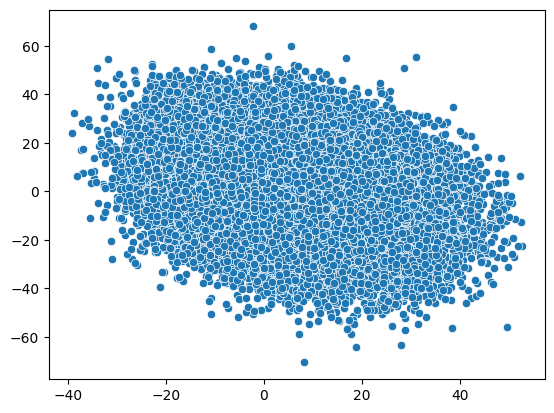

In [36]:
sns.scatterplot(
    x=x2d[:,0],
    y=x2d[:,1],
)

In [37]:
from sknetwork.clustering import Louvain, Leiden
from sknetwork.data import from_edge_list
from sknetwork.clustering.metrics import get_modularity

In [38]:
embeddings.keys()

dict_keys(['Conv_Mean_Dual', 'Conv_Mean_Margin_Structure_Prototypes', 'Conv_Mean_Rec_Dual_2', 'Conv_Mean_Dual_Aug', 'Conv_Mean_Rec', 'Conv_Mean_Structure_Rec', 'Conv_Mean_Rec_Dual', 'Conv_Mean_Aug', 'Conv_Mean_Margin_Structure_Prototypes_2', 'Conv_Mean_Margin_Structure_Aug', 'Conv_Mean_Margin_Structure', 'Conv_Mean'])

In [39]:
E = embeddings['Conv_Mean_Margin_Structure']['entities_embeddings_v1'] # data['Entity'].x
# C = embeddings['Conv_Mean_Margin_Structure_Prototypes_2']['C'] # data['Entity'].x
# S = E @ C.T
# E = S / torch.norm(S, dim=1, p=2, keepdim=True)
E = E / torch.norm(E, dim=1, p=2, keepdim=True)

In [40]:
from tqdm.auto import tqdm

def generate_threshold_based_graph(X : Tensor, threshold : float) -> tuple[Tensor, Tensor]:

    row, col = 0, 0
    edges = []
    weights = []

    batched = torch.split(X, 8192)

    with tqdm(total=1.0) as pbar:
    
        for l in batched:

            col = 0

            for r in batched:

                S = l @ r.T
                A = (S > threshold).type(torch.long)

                for src, dst in torch.argwhere(A):
                    edges.append((row + src.item(), col + dst.item()))
                    weights.append(A[src, dst].item())

                col += r.size(0)

                pbar.update(1 / (len(batched)**2))

    weights = torch.tensor(weights)
    edges = torch.tensor(edges).t()

    return edges, weights

In [41]:
louvain = Leiden(resolution=10)

edge_index, weights = generate_threshold_based_graph(E, 0.7)
print(edge_index.shape)
edge_index, weights = gnn_utils.remove_self_loops(edge_index, weights)
g_data = from_edge_list(edge_index.t().tolist())
p = louvain.fit_predict_proba(g_data)
i = p.argmax(-1)

 97%|█████████▋| 0.9722222222222225/1.0 [00:09<00:00,  8.44s/it]  /home/fellah-a/anaconda3/envs/text2kg-main/lib/python3.12/site-packages/tqdm/std.py:636: TqdmWarning:

clamping frac to range [0, 1]

100%|██████████| 1.0000000000000002/1.0 [00:09<-00:00,  9.76s/it]


torch.Size([2, 132526])


In [42]:
entities = np.array([e.id for e in graph._nodes['Entity']._nodes])
scores =  graph._nodes['Entity']._features['generality_scores'].numpy()

In [43]:
graph._nodes['Entity'].get_node('parameter').properties['degree']

98.0

In [44]:
def entropy(p : Tensor) -> Tensor:
    return - torch.sum(p * torch.log(p + 1e-6), dim=-1)

In [45]:
df = pd.DataFrame(data={
    "Entity" : entities,
    "Entropy" : entropy(torch.from_numpy(p)).numpy(),
    "Degree" : gnn_utils.degree(edge_index[0], num_nodes=E.shape[0]) + gnn_utils.degree(edge_index[1], num_nodes=E.shape[0]),
    "Community" : i,
    "generality_score" : graph._nodes['Entity']._features['generality_scores'],
    "relevancy_scores" : graph._nodes['Entity']._features['relevancy_scores'],
    "max_prob" : p.max(axis=-1),
    "N" : N
})

In [46]:
index = df['Community'].value_counts()
np.sum(index >= 50)

np.int64(334)

In [47]:
df[df['Community'] == 0].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
8741,simulation_model,6.991835e-01,48.0,0,0.672734,0.547901,0.854167,94.0
44952,complex_real_time_system,9.940936e-01,34.0,0,0.000002,0.408081,0.764706,90.0
10489,simulation_time,2.928803e-01,50.0,0,0.537918,0.563809,0.940000,87.0
320,simulation,5.868373e-01,129.0,0,0.894259,0.677687,0.891473,85.0
549,energy_sufficiency,1.340512e+00,78.0,0,0.014520,0.310713,0.641026,83.0
10118,physical_simulation,1.926227e-01,51.0,0,0.562767,0.546021,0.960784,72.0
10486,efficient_simulation_methodology,9.536801e-01,26.0,0,0.000002,0.337745,0.769231,71.0
866,numerical_simulation,1.382760e+00,58.0,0,0.880629,0.625861,0.551724,70.0
5647,simulation_method,2.588686e-01,103.0,0,0.431906,0.591190,0.951456,69.0
45456,simulation_engine,5.276525e-01,45.0,0,0.010823,0.475076,0.888889,69.0


In [48]:
df[df['Community'] == 1].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
811,optimization,1.031819,120.0,1,0.845415,0.644910,0.808333,167.0
682,optimization_problem,0.664368,100.0,1,0.795993,0.556380,0.870000,163.0
4388,optimization_process,0.621696,137.0,1,0.655899,0.518213,0.890511,137.0
1071,optimization_procedure,0.671755,121.0,1,0.433952,0.627852,0.876033,131.0
48537,optimization_challenge,0.443754,17.0,1,0.000001,0.626628,0.882353,130.0
22716,optimization_method,0.706394,59.0,1,0.498189,0.540155,0.847458,125.0
15065,optimization_algorithm,1.015903,48.0,1,0.746037,0.553731,0.750000,125.0
23929,algorithm_optimization,1.037902,18.0,1,0.000001,0.615278,0.722222,121.0
6538,combinatorial_optimization_problem,1.493535,74.0,1,0.357314,0.394101,0.689189,120.0
5453,optimization_technique,0.822714,110.0,1,0.493485,0.580180,0.818182,115.0


In [49]:
df[df['Community'] == 2].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1144,energy_saving,5.772213e-01,106.0,2,8.279832e-01,0.528659,0.886792,187.0
421,energy_efficiency,1.250554e+00,118.0,2,8.509839e-01,0.649042,0.635593,186.0
321,power_consumption,1.068031e+00,107.0,2,7.142670e-01,0.560908,0.785047,173.0
249,energy_consumption,7.597276e-01,132.0,2,8.351793e-01,0.554490,0.848485,169.0
3667,costs_of_energy,1.585069e+00,52.0,2,7.372056e-01,0.569857,0.615385,163.0
45629,future_energy_consumption,7.990532e-01,26.0,2,1.300763e-06,0.431303,0.807692,156.0
8604,electricity_consumption,3.858457e-01,46.0,2,7.182294e-01,0.460837,0.913043,147.0
3078,energy_intensive,1.119871e+00,34.0,2,4.349259e-01,0.687975,0.676471,144.0
2504,global_energy_consumption,6.651577e-01,113.0,2,3.794126e-01,0.557199,0.867257,141.0
5917,electrical_energy_consumption,4.955886e-01,77.0,2,4.256622e-01,0.415437,0.896104,135.0


In [50]:
df[df['Community'] == 3].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
32857,electromagnetic_sensor,1.073539e+00,8.0,3,1.104328e-01,0.346125,0.625000,90.0
2998,microwave_based_sensor,1.385865e+00,42.0,3,4.656619e-01,0.302267,0.595238,84.0
22119,optical_sensor,1.450798e+00,14.0,3,4.654909e-01,0.510721,0.571429,63.0
23932,temperature_stratification,1.945903e+00,7.0,3,2.422098e-01,0.490985,0.142857,63.0
5542,thin_film_sensor,1.023664e+00,26.0,3,1.951144e-06,0.472834,0.692308,61.0
19260,dielectric_layer,-9.999995e-07,1.0,3,4.396038e-01,0.538591,1.000000,59.0
17670,on_body_wireless_sensor,7.509638e-01,21.0,3,1.951144e-06,0.275106,0.809524,58.0
15226,renewable_energy_production,1.609433e+00,5.0,3,1.300763e-06,0.324572,0.200000,57.0
11976,quantum_sensor,1.333466e+00,16.0,3,3.567306e-01,0.465344,0.625000,56.0
6843,implantable_biomedical_sensor,1.761785e+00,54.0,3,1.951144e-06,0.518299,0.592593,56.0


In [51]:
df[df['Community'] == 4].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
10618,smart_city,5.623331e-01,8.0,4,4.199535e-01,0.506247,0.750000,84.0
32607,single_item_lot_sizing_problem,1.039718e+00,4.0,4,1.546945e-01,0.350674,0.500000,82.0
32613,multi_period_lot_sizing_problem,1.386290e+00,4.0,4,1.300763e-06,0.379746,0.250000,68.0
32610,optimal_lot_sizing_solution,1.609433e+00,5.0,4,1.300763e-06,0.436951,0.200000,64.0
148,internet_of_thing,1.536483e+00,81.0,4,6.462888e-01,0.516137,0.679012,62.0
36441,uncoordinated_iot_network,1.039718e+00,4.0,4,7.093643e-02,0.347381,0.500000,59.0
19058,internet_of_things_object,6.725860e-01,30.0,4,1.951144e-06,0.431431,0.833333,57.0
5291,internet_of_things_iot_system,1.299288e+00,89.0,4,4.437116e-01,0.434583,0.719101,56.0
31527,internet_of_things_physical_architecture,-9.999995e-07,11.0,4,1.300763e-06,0.293855,1.000000,55.0
8329,optimal_location,6.931452e-01,2.0,4,1.300763e-06,0.468708,0.500000,53.0


In [52]:
df[df['Community'] == 5].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5424,deep_convolutional_neural_network,0.830963,163.0,5,7.189130e-01,0.457132,0.840491,117.0
6788,deep_learning_model,0.849926,134.0,5,5.952637e-01,0.456414,0.828358,134.0
7696,deep_learning_algorithms,1.295543,130.0,5,6.412636e-01,0.480167,0.630769,171.0
2407,deep_learning,0.388718,123.0,5,7.327433e-01,0.507136,0.926829,104.0
1034,residual_deep_convolutional_neural_network_model,0.727539,108.0,5,1.300763e-06,0.401973,0.851852,67.0
5363,deep_learning_based_framework,0.622765,92.0,5,1.300763e-06,0.427223,0.858696,86.0
7563,deep_learning_system,0.578976,89.0,5,4.327312e-03,0.506916,0.887640,102.0
5143,deep_learning_method,1.002533,87.0,5,6.672421e-01,0.524557,0.781609,98.0
2465,deep_learning_based_strategy,1.015078,86.0,5,1.300763e-06,0.564689,0.755814,69.0
5563,backpropagation_algorithm,1.504212,84.0,5,2.730528e-02,0.383982,0.595238,38.0


In [53]:
df[df['Community'] == 8].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4257,sustainable_construction,0.906108,94.0,8,1.300763e-06,0.551847,0.702128,22.0
1676,mobile_robot,1.371833,89.0,8,4.744909e-01,0.457884,0.662921,15.0
7601,hybrid_parallel_robot,1.001165,84.0,8,1.951144e-06,0.452947,0.642857,16.0
913,activated_carbon_from_wood,1.571100,80.0,8,1.951144e-06,0.429486,0.650000,10.0
2785,workshop,1.042923,77.0,8,7.263107e-01,0.692340,0.766234,2.0
7143,charge_distribution,1.016253,76.0,8,1.300763e-06,0.762973,0.763158,2.0
1681,active_rolling,0.849108,73.0,8,1.951144e-06,0.546178,0.767123,1.0
2936,electrical_field,0.718096,71.0,8,1.951144e-06,0.615153,0.830986,5.0
6247,scenario_based_mixed_integer_linear_programming,0.675123,70.0,8,6.503813e-07,0.306093,0.771429,22.0
2937,electrical_stability,1.056320,69.0,8,3.474408e-01,0.507511,0.768116,14.0


In [54]:
df[df['Community'] == 9].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
22,image_acquisition,1.768009,59.0,9,0.000002,0.533746,0.576271,14.0
737,imaging,1.339154,44.0,9,0.789668,0.628020,0.681818,16.0
7497,operational_constraint,1.426947,42.0,9,0.421000,0.580971,0.452381,3.0
1499,brain,1.584680,39.0,9,0.304658,0.576995,0.512821,0.0
3217,ly_son,2.000570,36.0,9,0.000001,0.630443,0.416667,2.0
4087,dynamic_spectrum_access,0.644478,34.0,9,0.306743,0.529890,0.823529,4.0
184,imaging_technique,1.143120,33.0,9,0.420970,0.595140,0.696970,13.0
5198,environmental_degradation,1.441186,32.0,9,0.578743,0.581182,0.593750,16.0
6079,numerical_tool,1.532101,31.0,9,0.522603,0.645679,0.580645,6.0
237,camera_image_processing,1.576954,30.0,9,0.000002,0.487998,0.466667,15.0


In [55]:
df[df['Community'] == 7].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
159,energy_storage,1.130346,79.0,7,0.708130,0.553446,0.759494,76.0
7276,battery_storage,1.368371,65.0,7,0.325996,0.500816,0.692308,46.0
2430,integrated_thermal_energy_storage,1.690064,60.0,7,0.444661,0.409431,0.600000,34.0
464,battery,2.430253,54.0,7,0.654507,0.562408,0.277778,77.0
522,specimen,1.838892,51.0,7,0.652662,0.648319,0.529412,0.0
6598,energy_storage_device,1.220975,50.0,7,0.546476,0.546103,0.720000,43.0
7222,energy_storage_solution,2.432157,48.0,7,0.307644,0.492642,0.333333,59.0
630,maintenance,1.839302,44.0,7,0.798159,0.653909,0.477273,57.0
7370,flexible_solution,1.242667,39.0,7,0.314180,0.681268,0.666667,4.0
267,storage,0.994837,38.0,7,0.809745,0.665640,0.763158,11.0


In [56]:
df[df['Community'] == 6].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
3629,diffusion_model,1.873350,47.0,6,5.334759e-01,0.587930,0.510638,16.0
2037,feature_extraction,1.666828,44.0,6,6.748743e-01,0.512240,0.522727,63.0
1756,thin_film,1.074606,44.0,6,6.971353e-01,0.586568,0.727273,57.0
4254,image_dataset,1.569162,44.0,6,6.503813e-07,0.734263,0.636364,32.0
6393,thin_film_technology,1.217698,40.0,6,5.103301e-01,0.451978,0.700000,102.0
5848,reactive_dc_magnetron_sputtering,1.630330,38.0,6,5.828776e-01,0.500549,0.605263,25.0
6590,vanadium_nitride,1.349282,36.0,6,2.590104e-01,0.357893,0.666667,23.0
6655,window,0.914781,36.0,6,6.214162e-01,0.696592,0.777778,0.0
3768,pulsed_plasma_enhanced_chemical_vapor_deposition,1.553626,35.0,6,1.665230e-01,0.339710,0.542857,16.0
6948,aln_molecular_beam_epitaxy,1.669195,34.0,6,6.816390e-01,0.565245,0.500000,9.0


In [57]:
df[df['Community'] == 10].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
7546,design_process,1.977399,69.0,10,0.824731,0.638508,0.507246,9.0
4746,system_design,1.114213,64.0,10,0.605438,0.606184,0.765625,17.0
6274,more_than_human_design_practice,0.806168,49.0,10,0.000001,0.292812,0.795918,13.0
7313,spoilage,1.399500,46.0,10,0.352303,0.470552,0.652174,22.0
4256,fully_metallic_additive_manufacturing,1.977215,44.0,10,0.715877,0.506692,0.454545,73.0
7314,microbiota,1.465028,42.0,10,0.000002,0.549863,0.595238,10.0
351,design,0.797868,41.0,10,0.927872,0.704092,0.804878,23.0
7315,biochemical_change,0.712583,41.0,10,0.000002,0.539521,0.780488,14.0
7316,sensory_characteristic,0.992873,40.0,10,0.000002,0.608861,0.775000,1.0
373,designer,1.264640,38.0,10,0.796245,0.685710,0.447368,11.0


In [58]:
df[df['Community'] == 11].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4542,operations_and_supply_chain_management,1.347990,37.0,11,4.052148e-01,0.364085,0.648649,60.0
627,standardization,1.399598,37.0,11,8.413602e-01,0.617710,0.648649,22.0
821,supply_chain_management,0.576052,37.0,11,5.107070e-01,0.410770,0.864865,36.0
3100,jute_fuselage,1.762423,32.0,11,1.951144e-06,0.408340,0.406250,1.0
5668,resilience_of_supply_chain,1.311614,30.0,11,4.445587e-01,0.344283,0.666667,61.0
1509,modern_supply_chain,1.158352,28.0,11,2.709752e-01,0.423336,0.642857,10.0
284,vectorized_representation,2.044848,27.0,11,1.951144e-06,0.476636,0.370370,4.0
4670,world,1.827447,26.0,11,6.370589e-01,0.696665,0.423077,10.0
6228,neuromorphic_device,1.703347,26.0,11,6.503813e-07,0.356067,0.423077,12.0
2707,precedence_constraint_structure,0.642594,26.0,11,5.378312e-01,0.564587,0.846154,15.0


In [59]:
df[df['Community'] == 12].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
443,uncertainty,1.002684,68.0,12,0.841966,0.656636,0.779412,44.0
2208,search,2.504675,33.0,12,0.744729,0.720433,0.303030,3.0
7470,epistemic_uncertainty,0.598226,32.0,12,0.345473,0.541204,0.843750,24.0
7469,aleatoric_uncertainty,0.611948,31.0,12,0.443706,0.649371,0.838710,53.0
4280,tenant,0.793394,31.0,12,0.000003,0.588575,0.806452,0.0
7468,uncertainties_handling,1.744212,30.0,12,0.000001,0.544063,0.433333,16.0
4915,global_energy_demand,1.359553,29.0,12,0.362697,0.539973,0.551724,57.0
3482,worst_case_scenario,0.592398,29.0,12,0.323312,0.637986,0.862069,31.0
7974,french_national_microelectronics_network,1.608847,28.0,12,0.260508,0.602355,0.464286,5.0
12472,uncertainty_analysis,1.137800,25.0,12,0.602911,0.499154,0.720000,28.0


In [60]:
df[df['Community'] == 13].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4468,machine_learning_model,1.049598,106.0,13,0.767804,0.483984,0.764151,196.0
7255,machine_learning_method,1.267195,96.0,13,0.716247,0.486755,0.718750,134.0
6084,machine_learning_algorithms,1.059399,89.0,13,0.593282,0.506500,0.764045,136.0
2,machine_learning,0.981243,88.0,13,0.738132,0.476801,0.784091,181.0
4152,advanced_machine_learning_model,2.062535,83.0,13,0.000002,0.591745,0.457831,165.0
3910,reinforcement_learning_algorithm,1.805580,80.0,13,0.409496,0.365796,0.387500,59.0
4102,machine_learning_based_method,0.402002,71.0,13,0.000001,0.416495,0.915493,132.0
6257,artificial_intelligence_machine_learning_ai_ml,1.699942,69.0,13,0.000002,0.444120,0.463768,143.0
568,machine_learning_assisted_localization_technique,0.795005,62.0,13,0.000002,0.280689,0.822581,112.0
1156,model_based_machine_learning_paradigm,0.763271,60.0,13,0.000002,0.260242,0.800000,106.0


In [61]:
df[df['Community'] == 14].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
7040,robotic_assisted_minimally_invasive_pancreatic...,0.943371,48.0,14,0.000002,0.224906,0.770833,15.0
4133,predictive_maintenance_technique,0.765780,26.0,14,0.624609,0.550706,0.653846,8.0
2379,substitution,1.097107,26.0,14,0.000001,0.848550,0.692308,9.0
1921,markov_decision_process,2.122046,22.0,14,0.397894,0.456655,0.363636,2.0
4209,laparoscopic_pancreatic_surgery,1.524419,21.0,14,0.161145,0.244956,0.523810,14.0
2370,images_of_the_same_size,1.153117,21.0,14,0.000001,0.770359,0.666667,4.0
28709,parallel_robots_latest_technology,1.306906,20.0,14,0.000001,0.307910,0.500000,20.0
2376,cohort_image,1.513657,19.0,14,0.000001,0.621185,0.526316,5.0
31,anomaly_detection,1.658103,18.0,14,0.528479,0.378596,0.444444,85.0
3137,passivation,0.916064,17.0,14,0.000002,0.489513,0.705882,20.0


In [62]:
df[df['Community'] == 15].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
587,stability,1.089288,101.0,15,8.988757e-01,0.677702,0.792079,50.0
6753,stable_equilibrium,1.129849,81.0,15,4.619740e-01,0.537919,0.703704,21.0
1237,stability_analysis,0.897139,73.0,15,5.071416e-01,0.567174,0.794521,39.0
6028,taylor_series_stability,1.169452,67.0,15,6.503813e-07,0.771449,0.641791,19.0
40,stabilization,0.897014,61.0,15,4.444982e-01,0.612116,0.786885,41.0
2168,design_principle,1.734587,56.0,15,6.503813e-07,0.590549,0.464286,18.0
1097,passive_stability,1.438793,52.0,15,1.300763e-06,0.555149,0.653846,44.0
6027,robust_stabilization,1.110956,50.0,15,2.715849e-01,0.547901,0.640000,18.0
2167,channel_control,1.038245,45.0,15,2.601525e-06,0.575654,0.755556,0.0
103,equilibrium,1.031086,42.0,15,8.113714e-01,0.675636,0.761905,10.0


In [63]:
df[df['Community'] == 16].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
8103,truck_departure_time,1.672113,65.0,16,0.000001,0.459055,0.400000,21.0
7481,transportation_cost,1.384887,64.0,16,0.507619,0.547056,0.656250,54.0
5750,ensemble_learning_model,2.223282,62.0,16,0.000002,0.528205,0.258065,63.0
3879,waste_oil,1.316032,50.0,16,0.000002,0.669267,0.600000,4.0
2523,multimodal_transportation,1.359506,47.0,16,0.000001,0.389135,0.617021,25.0
5261,vehicle_routing_problem,1.129684,47.0,16,0.407782,0.337511,0.702128,57.0
91,clinician,1.267000,46.0,16,0.672127,0.622227,0.695652,16.0
2522,logistics_network,0.859635,46.0,16,0.696498,0.689667,0.760870,83.0
8114,bio_based_composite_sandwich_structure,2.146902,41.0,16,0.000002,0.306510,0.439024,2.0
6572,phase_evolution,0.968402,36.0,16,0.000001,0.582209,0.722222,2.0


In [64]:
df[df['Community'] == 17].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
3294,autonomous_vehicle,1.526998e+00,70.0,17,6.070997e-01,0.478407,0.657143,31.0
6630,novice_pilot,2.169703e+00,40.0,17,2.276334e-06,0.467914,0.350000,3.0
6979,llm_annotator,1.983709e+00,35.0,17,1.300763e-06,0.351070,0.428571,31.0
4817,adsorption_based_process,1.544375e+00,34.0,17,1.951144e-06,0.519801,0.470588,21.0
6317,gdo,1.385882e+00,34.0,17,5.622807e-01,0.822918,0.617647,2.0
7046,control_performance,1.131395e+00,30.0,17,5.392016e-01,0.592879,0.700000,10.0
5725,gelatinization,6.924172e-01,26.0,17,6.503813e-07,0.420460,0.807692,32.0
3257,connected_and_autonomous_vehicle,9.003621e-01,26.0,17,4.520342e-01,0.404736,0.769231,13.0
2897,cloud_infrastructure,1.593322e+00,25.0,17,4.939086e-01,0.425774,0.480000,26.0
1432,scribner_technology,1.201676e+00,25.0,17,1.951144e-06,0.772578,0.640000,6.0


In [65]:
df[df['Community'] == 18].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5227,obesity,1.646369,29.0,18,1.868604e-01,0.611717,0.551724,10.0
7789,united_states_of_america,1.257127,25.0,18,8.935757e-01,0.803590,0.640000,7.0
541,electrode_surface,1.522807,22.0,18,4.297495e-01,0.507005,0.545455,36.0
1400,europe,1.189880,20.0,18,8.227073e-01,0.686385,0.650000,19.0
5231,oleic_acid,1.504779,20.0,18,1.300763e-06,0.620939,0.600000,3.0
5142,visualization,1.559574,16.0,18,7.663348e-01,0.599193,0.500000,20.0
6635,participants_performance,1.754098,16.0,18,2.276334e-06,0.743872,0.375000,3.0
5232,micro_calcification,0.627702,15.0,18,5.839019e-01,0.526638,0.800000,11.0
5229,lipid_body_droplet,0.796309,14.0,18,1.300763e-06,0.403501,0.714286,15.0
1303,generalized_linear_regression,0.994349,14.0,18,1.951144e-06,0.488936,0.714286,11.0


In [66]:
df[df['Community'] == 19].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
459,renewable_energy_resource,1.799634,55.0,19,0.513489,0.488627,0.490909,79.0
458,renewable_energy_supply,1.605288,47.0,19,0.381668,0.475173,0.595745,50.0
3932,physiological_process,1.974707,44.0,19,0.000003,0.636410,0.500000,3.0
12124,renewable_energy_source,2.408904,38.0,19,0.584631,0.450933,0.394737,83.0
7454,renewable_energy_system,1.613834,30.0,19,0.383139,0.395332,0.500000,42.0
4697,dynamic_of_creativity,2.490510,28.0,19,0.000002,0.527087,0.285714,4.0
3055,guided_resource_optimization,1.065567,26.0,19,0.000003,0.485733,0.653846,6.0
5091,phase_tuning_curve,1.535847,24.0,19,0.000002,0.481926,0.541667,4.0
4032,instrumentation,2.102842,21.0,19,0.638241,0.642429,0.428571,76.0
2115,renewable_source,1.773667,20.0,19,0.422295,0.520462,0.350000,35.0


In [67]:
df[df['Community'] == 20].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
6766,diffusion_rate,1.528634e+00,45.0,20,1.300763e-06,0.481761,0.600000,18.0
921,diffusion,1.893114e+00,44.0,20,8.432915e-01,0.638991,0.522727,37.0
1830,diffusivity,1.778408e+00,36.0,20,1.300763e-06,0.607682,0.472222,17.0
6147,inverse_kinematics_model,6.318741e-01,33.0,20,4.225862e-01,0.397098,0.818182,18.0
1669,migration_test,1.463428e+00,32.0,20,1.951144e-06,0.622036,0.625000,7.0
3511,diffusivity_model,9.734893e-01,31.0,20,1.300763e-06,0.486195,0.741935,14.0
6229,memristive_property,1.305493e+00,31.0,20,6.503813e-07,0.499025,0.645161,13.0
3513,chloride_measurement,-9.999995e-07,30.0,20,1.300763e-06,0.403467,1.000000,10.0
1667,chloride_diffusivity,5.757265e-01,29.0,20,3.744193e-01,0.393697,0.827586,34.0
3512,diffusion_test_method,5.923979e-01,29.0,20,1.300763e-06,0.395099,0.862069,10.0


In [68]:
df[df['Community'] == 21].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4806,virtual_environment,1.971527,77.0,21,0.691458,0.465948,0.402597,38.0
1506,virtual_reality,1.307409,62.0,21,0.660343,0.463274,0.709677,49.0
6131,external_sound_source,2.245760,49.0,21,0.000002,0.543765,0.387755,4.0
6629,virtual_reality_headset,1.739352,45.0,21,0.273080,0.401702,0.577778,45.0
2619,f_score,0.914781,36.0,21,0.000002,0.551985,0.777778,1.0
2565,interdependency,1.543926,36.0,21,0.493001,0.663827,0.527778,2.0
6676,dof_cable_driven_exosuit,1.201416,34.0,21,0.000001,0.266638,0.676471,0.0
5224,immersive_head_mounted_display,1.437970,34.0,21,0.519168,0.434973,0.588235,38.0
4090,mixed_reality,1.504126,34.0,21,0.441779,0.452583,0.588235,8.0
3124,bio_inspired_robotic_wrist,1.476969,32.0,21,0.000001,0.475917,0.562500,4.0


In [69]:
df[df['Community'] == 22].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5400,traditional_parallel_robot,1.047926,96.0,22,0.000001,0.449347,0.760417,42.0
6639,immersive_experience,1.428485,76.0,22,0.623556,0.506719,0.500000,60.0
36,earthen_structure,1.893204,73.0,22,0.000002,0.547589,0.397260,10.0
34,image,1.696814,65.0,22,0.780661,0.628661,0.538462,27.0
4079,device_autonomy,1.084542,58.0,22,0.000002,0.601514,0.603448,0.0
5775,durability,1.360792,54.0,22,0.725342,0.600444,0.685185,48.0
1776,orthotropic_architecture,1.142121,54.0,22,0.000002,0.564224,0.703704,13.0
2553,empirical_datum,0.733350,52.0,22,0.000001,0.700664,0.769231,17.0
2555,rd_cleanroom_setting,0.893336,51.0,22,0.000001,0.465235,0.686275,0.0
1775,mechanical_response,2.050142,51.0,22,0.660502,0.527400,0.450980,19.0


In [70]:
df[df['Community'] == 23].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
703,organic_material,2.690655,63.0,23,0.577235,0.508785,0.333333,7.0
4019,polymer_composite,1.429530,61.0,23,0.355838,0.369749,0.606557,68.0
1010,climate_change,1.814792,54.0,23,0.803138,0.514860,0.462963,26.0
1222,polymer,1.225029,47.0,23,0.773008,0.560807,0.680851,21.0
5053,pharmaceutical_application,1.546998,44.0,23,0.448007,0.566277,0.477273,3.0
5763,carbon_fiber_reinforced_polymer,1.877658,42.0,23,0.000003,0.395726,0.476190,13.0
3637,electrolysis,2.342532,37.0,23,0.276504,0.560306,0.297297,18.0
5924,scaled_submarine_model,1.807779,35.0,23,0.000002,0.529286,0.485714,17.0
6117,polymer_matrix,1.384456,35.0,23,0.654702,0.533824,0.628571,28.0
3384,exocytosis,1.382477,35.0,23,0.000002,0.385291,0.628571,12.0


In [71]:
df[df['Community'] == 24].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
7262,solar_panel,1.638136,56.0,24,0.610186,0.475089,0.553571,40.0
2431,solar_power_plant,2.183932,56.0,24,0.000001,0.531658,0.339286,9.0
7518,solar_photovoltaic_energy,1.694605,55.0,24,0.396118,0.423230,0.581818,39.0
3450,photovoltaic_pv_panel,0.560641,46.0,24,0.514268,0.415420,0.869565,21.0
138,rotor,0.972973,41.0,24,0.370343,0.449416,0.536585,10.0
3406,unstable_solution,1.718737,41.0,24,0.000001,0.554694,0.463415,2.0
1148,pv_technology,1.437064,37.0,24,0.000001,0.382245,0.648649,30.0
6322,impurity,1.940651,36.0,24,0.552608,0.696311,0.361111,24.0
20,earthen_construction,1.249238,30.0,24,0.000002,0.503737,0.566667,5.0
3455,photovoltaic_performance,1.311614,30.0,24,0.358043,0.366751,0.666667,16.0


In [72]:
df[df['Community'] == 25].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
213,industry,1.709948e+00,27.0,25,0.794090,0.652341,0.444444,59.0
6622,time_delay,1.465309e+00,24.0,25,0.700412,0.573711,0.583333,6.0
1089,tensegrity_system,1.335597e+00,21.0,25,0.000001,0.463380,0.571429,28.0
5156,unsupervised_learning,1.163717e+00,20.0,25,0.603665,0.501232,0.650000,10.0
5065,low_impact_supplier,1.407143e+00,19.0,25,0.000002,0.523335,0.473684,10.0
7390,neural_architecture_search,1.822448e+00,19.0,25,0.184771,0.464645,0.421053,16.0
4727,operational_dimension,1.714734e+00,18.0,25,0.000002,0.592241,0.500000,2.0
5066,module,4.659973e-01,17.0,25,0.615440,0.620738,0.823529,2.0
253,first_layer,1.773097e+00,17.0,25,0.000002,0.776676,0.470588,16.0
2247,long_term_durability,1.461124e+00,17.0,25,0.565548,0.577348,0.411765,54.0


In [73]:
df[df['Community'] == 26].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
6993,in_situ_observation,0.971258,50.0,26,1.300763e-06,0.632826,0.780000,2.0
6469,energy_source,1.728899,42.0,26,6.383050e-01,0.531797,0.523810,70.0
6121,short_fibre,1.082127,32.0,26,2.710445e-01,0.641411,0.718750,8.0
6514,heterodyne_velocimetry,1.367090,31.0,26,1.951144e-06,0.611305,0.645161,1.0
6553,void,1.192329,26.0,26,3.775678e-01,0.610530,0.653846,3.0
7420,numerical_case,1.032186,25.0,26,2.276334e-06,0.721168,0.600000,0.0
776,sensing_capability,0.450559,24.0,26,2.601525e-06,0.536153,0.833333,6.0
6515,substructure,0.847034,24.0,26,4.639758e-01,0.698418,0.791667,0.0
4708,port_of_douala,0.752913,23.0,26,1.951144e-06,0.591300,0.782609,5.0
6552,production_plan,1.324092,23.0,26,3.394372e-01,0.438297,0.565217,12.0


In [74]:
df[df['Community'] == 27].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4258,soils_suitable_for_d_printing,5.432875e-01,40.0,27,1.300763e-06,0.342878,0.875000,17.0
19,d_printing_process,1.102599e+00,36.0,27,5.566659e-01,0.583394,0.694444,48.0
6710,biodiesel_production_efficiency,1.664719e+00,35.0,27,1.300763e-06,0.277487,0.542857,49.0
1766,d_printed_part,4.845266e-01,34.0,27,4.654067e-01,0.641778,0.882353,34.0
731,full_field_deformation,8.454986e-01,33.0,27,1.951144e-06,0.446214,0.787879,15.0
35,d_printing,-9.999995e-07,33.0,27,7.153918e-01,0.701048,1.000000,69.0
1064,coherent_near_field_source,1.586328e+00,29.0,27,6.503813e-07,0.282596,0.448276,7.0
6709,natural_source,8.765247e-01,27.0,27,1.300763e-06,0.642742,0.777778,9.0
4201,d_printed_biocomposite,1.429157e+00,26.0,27,2.276334e-06,0.409708,0.576923,4.0
4267,plastic_limit,9.256444e-01,25.0,27,1.300763e-06,0.555962,0.760000,5.0


In [75]:
df[df['Community'] == 28].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
2254,raman_spectroscopy_spectra,1.109093e+00,57.0,28,0.743317,0.480633,0.719298,40.0
1139,cadmium_telluride,1.059162e+00,33.0,28,0.000001,0.519229,0.727273,7.0
2276,raman_spectroscopy_with_chemometric_analysis,1.676128e+00,29.0,28,0.000002,0.251044,0.551724,20.0
5753,coefficient_of_determination,1.939349e+00,28.0,28,0.524580,0.588220,0.285714,2.0
487,volumetric_grain_size_distribution,1.156703e+00,27.0,28,0.000002,0.416611,0.481481,2.0
5852,x_ray_photoelectron_spectroscopy,1.603177e+00,24.0,28,0.684322,0.382421,0.500000,61.0
9331,raman_spectra,1.171186e+00,24.0,28,0.683462,0.474500,0.708333,45.0
2764,initial_shape,6.428539e-01,23.0,28,0.000002,0.707064,0.826087,9.0
4052,dataflow_model_of_computation,2.077096e+00,23.0,28,0.326640,0.343165,0.260870,33.0
1626,optical_photothermal_infrared_spectroscopy,1.483578e+00,22.0,28,0.000002,0.462345,0.545455,15.0


In [76]:
df[df['Community'] == 29].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1173,ultrafast_d_nmr_method,2.025048,50.0,29,2.478268e-01,0.339058,0.280000,19.0
2653,persistent_organic_pollutant,1.043062,41.0,29,6.503813e-07,0.620478,0.731707,3.0
5594,tetradecane,0.823717,40.0,29,3.783892e-01,0.584802,0.600000,2.0
1555,benchtop_nuclear_magnetic_resonance,0.976411,38.0,29,6.974975e-01,0.608328,0.710526,17.0
4792,host_structure,1.665558,35.0,29,1.951144e-06,0.611531,0.514286,12.0
781,fundamental_mode,0.132689,34.0,29,2.601525e-06,0.612053,0.970588,0.0
4794,mgalohfcmono_electrode_material,0.940279,34.0,29,1.951144e-06,0.379961,0.735294,33.0
4124,thermal_insulation_layer,0.453348,33.0,29,6.503813e-07,0.548742,0.878788,3.0
489,closed_form_tpcf,1.435043,30.0,29,2.276334e-06,0.482222,0.566667,0.0
8973,quantitative_nmr_analysis,0.434940,30.0,29,1.300763e-06,0.322252,0.900000,33.0


In [77]:
df[df['Community'] == 30].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5740,human_centered_ai_workflow,0.971812,84.0,30,0.000002,0.457251,0.797619,12.0
5736,ethical_implication,0.460440,62.0,30,0.000002,0.660745,0.887097,33.0
6447,healthcare_delivery,0.931201,62.0,30,0.000003,0.562643,0.709677,7.0
5738,transparent_ai_workflow,0.332936,61.0,30,0.000002,0.441323,0.934426,6.0
5737,methodological_implication,0.236481,58.0,30,0.000002,0.543562,0.948276,27.0
5739,explainable_ai_workflow,0.632908,56.0,30,0.000002,0.535509,0.857143,12.0
5454,ai_deployment,0.518491,55.0,30,0.000001,0.553410,0.872727,8.0
4698,dynamic_of_organizational_recursion,1.891883,50.0,30,0.000002,0.445428,0.520000,1.0
569,computational_complexity,1.895766,48.0,30,0.774244,0.603349,0.479167,35.0
6795,linear_genetic_program,1.338201,47.0,30,0.000002,0.335976,0.638298,3.0


In [78]:
df[df['Community'] == 31].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
7690,adaptive_control_strategy,1.562700e+00,34.0,31,0.000002,0.374893,0.558824,12.0
8083,consumption,1.107383e+00,31.0,31,0.752422,0.679171,0.516129,22.0
6779,cement_hydration,1.355850e+00,27.0,31,0.390639,0.418124,0.518519,74.0
6777,microscopic_scale,1.085692e+00,26.0,31,0.575899,0.588078,0.653846,7.0
7684,super_twisting_sliding_mode_algorithm,4.396679e-01,25.0,31,0.000002,0.321491,0.840000,10.0
7685,above_rated_wind_speed,1.593322e+00,25.0,31,0.000002,0.508353,0.480000,3.0
7683,robust_adaptive_control_strategy,7.315111e-01,24.0,31,0.000002,0.300044,0.791667,16.0
6749,passive_tensegrity_system,1.196705e+00,24.0,31,0.000001,0.304310,0.625000,6.0
3544,sensitivity_analysis_integration,5.825812e-01,23.0,31,0.000002,0.614657,0.826087,25.0
5218,maximal_absolute_deviation,1.198812e+00,22.0,31,0.000001,0.762996,0.636364,2.0


In [79]:
df[df['Community'] == 32].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5359,digital_camera,6.575949e-01,28.0,32,0.000001,0.634250,0.821429,9.0
304,laser,1.593322e+00,25.0,32,0.750617,0.581182,0.480000,9.0
5361,content_creation,4.702330e-01,23.0,32,0.000001,0.652011,0.869565,4.0
5362,compression_artifact,1.227737e+00,23.0,32,0.346337,0.547568,0.608696,8.0
5372,film_grain_generation,1.730174e+00,19.0,32,0.000001,0.249351,0.473684,10.0
5366,synthesis_network,7.335377e-01,19.0,32,0.000001,0.617392,0.789474,3.0
5377,hydration,1.560703e+00,18.0,32,0.589260,0.551020,0.500000,1.0
5355,tree_structure_traversal,1.193937e+00,18.0,32,0.000001,0.468286,0.611111,8.0
7075,new_know_how,2.145572e-01,18.0,32,0.154106,0.702762,0.944444,3.0
5373,film_grain_synthesis,5.783223e-01,17.0,32,0.290629,0.356888,0.823529,4.0


In [80]:
df[df['Community'] == 33].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
791,finite_element_simulation,1.791249,75.0,33,7.290524e-01,0.500498,0.413333,42.0
505,new_finite_element_based_method,0.771596,39.0,33,7.433689e-01,0.520094,0.769231,61.0
4835,n_adsorption_isotherm,2.131645,39.0,33,1.975777e-01,0.473203,0.282051,14.0
4843,interlayer_microporosity,1.878028,36.0,33,1.951144e-06,0.508496,0.416667,23.0
1323,channel_estimation,1.966210,35.0,33,3.969271e-01,0.490457,0.485714,5.0
1537,task,1.880109,33.0,33,7.853715e-01,0.636387,0.424242,10.0
3379,pheochromocytoma_cell,1.918579,32.0,33,1.951144e-06,0.460554,0.375000,2.0
3894,security_guarantee,1.754122,27.0,33,6.503813e-07,0.563134,0.407407,9.0
1734,flavouring,1.540639,25.0,33,2.276334e-06,0.477091,0.480000,2.0
5319,large_eddy_simulation,1.164224,25.0,33,3.965098e-01,0.391232,0.520000,23.0


In [81]:
df[df['Community'] == 34].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4988,software_level_mitigation_technique,1.068846,39.0,34,0.000002,0.429127,0.692308,11.0
1153,signal_processing_technique,1.444568,39.0,34,0.580997,0.454863,0.641026,48.0
4995,cache_based_side_channel_attack,1.370895,32.0,34,0.000002,0.332152,0.593750,10.0
1162,channel_compression,1.790421,30.0,34,0.000002,0.647987,0.433333,5.0
4994,attacks_targeting_the_microarchitecture,1.342565,29.0,34,0.000002,0.301824,0.655172,13.0
4419,resonant_metamaterial,2.601666,28.0,34,0.000002,0.410529,0.214286,42.0
4814,biogas_upgrading_technique,1.437695,28.0,34,0.310310,0.368678,0.428571,20.0
2177,decomposition,2.098135,26.0,34,0.704764,0.604070,0.307692,3.0
4986,control_flow_hijacking_attack,0.870194,25.0,34,0.000002,0.330821,0.760000,11.0
4154,centralized_performance,1.551962,21.0,34,0.000002,0.591287,0.476190,1.0


In [82]:
df[df['Community'] == 35].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
3645,mixed_model,1.726133,35.0,35,4.632243e-01,0.637697,0.457143,17.0
1416,numerical_model,1.181624,22.0,35,8.123168e-01,0.630127,0.681818,60.0
3077,rocket_fuselage,1.816015,21.0,35,1.951144e-06,0.490855,0.476190,30.0
3009,rogers_ro_substrate,1.309750,19.0,35,2.601525e-06,0.674413,0.578947,12.0
3493,numerical_method,1.329656,18.0,35,8.093166e-01,0.640057,0.500000,31.0
2441,numerical_modelling,0.556644,18.0,35,6.723590e-01,0.611633,0.833333,96.0
314,shadow_region,0.871776,17.0,35,6.503813e-07,0.642263,0.764706,6.0
3646,h_production,1.037387,16.0,35,6.148922e-01,0.546171,0.687500,11.0
7542,discipline,1.333466,16.0,35,3.838251e-01,0.796849,0.625000,4.0
4950,authigenic_carbonate_fluorapatite,0.949589,15.0,35,1.300763e-06,0.444971,0.733333,6.0


In [83]:
df[df['Community'] == 36].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
7103,nanotechnology,2.492162e+00,38.0,36,6.417589e-01,0.506276,0.236842,31.0
6548,scenario_based_decomposition,1.762488e+00,31.0,36,2.998365e-01,0.492080,0.516129,31.0
5696,precious_compound,2.005713e+00,28.0,36,6.503813e-07,0.704271,0.357143,0.0
3662,embedded_multi_core_platform,6.248553e-01,27.0,36,1.300899e-01,0.385197,0.851852,16.0
4976,approximate_operator,5.359580e-01,26.0,36,1.300763e-06,0.379532,0.846154,7.0
1810,highly_luminescent_cui_dimetallic_complex,7.892724e-01,24.0,36,2.601525e-06,0.217028,0.791667,31.0
7259,learnable_parameter,1.324092e+00,23.0,36,1.300763e-06,0.806618,0.565217,25.0
3034,starch_content,1.468939e+00,20.0,36,1.300763e-06,0.437246,0.550000,17.0
2324,self_supervised_learning,1.367732e+00,19.0,36,1.300763e-06,0.358924,0.526316,9.0
1541,resource_limited_platform,1.862701e+00,19.0,36,2.823936e-01,0.722684,0.368421,2.0


In [84]:
df[df['Community'] == 37].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
523,performance,1.086048,66.0,37,0.910799,0.676032,0.666667,31.0
6419,purification_efficiency,1.875260,59.0,37,0.000001,0.519669,0.525424,13.0
3471,technical_performance,0.795397,57.0,37,0.500898,0.699167,0.824561,18.0
1907,performance_metric,1.754302,51.0,37,0.808474,0.630004,0.549020,29.0
7186,performance_indicator,1.347731,50.0,37,0.612468,0.706624,0.680000,9.0
325,performance_optimization,1.855641,47.0,37,0.373507,0.529118,0.404255,42.0
4104,system_performance,1.266026,47.0,37,0.816920,0.619557,0.702128,16.0
1120,performance_analysis,0.687832,41.0,37,0.534224,0.659098,0.829268,14.0
319,evaluation_performance,0.976840,37.0,37,0.810651,0.700724,0.756757,29.0
22803,performance_quantification,1.015948,33.0,37,0.000001,0.606949,0.757576,24.0


In [85]:
df[df['Community'] == 38].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
6067,environmental_sustainability,2.032705,70.0,38,6.051173e-01,0.518797,0.471429,65.0
3106,sustainability,1.624751,52.0,38,8.331550e-01,0.598773,0.557692,87.0
1573,sustainable_development_goal,1.258862,37.0,38,5.353138e-01,0.562648,0.621622,36.0
1,global_greenhouse_gas_emission,1.576820,31.0,38,3.401767e-01,0.464170,0.580645,60.0
1763,electron,2.034184,29.0,38,6.177796e-01,0.639115,0.413793,6.0
7358,machine_degradation,1.962014,29.0,38,2.926716e-06,0.467696,0.310345,1.0
0,construction_sector,1.481620,28.0,38,4.975127e-01,0.583898,0.571429,17.0
6037,method_used_in_spacecraft_oriented_tool,1.236831,25.0,38,1.951144e-06,0.394729,0.680000,1.0
8189,edge_platform,1.353356,25.0,38,1.951144e-06,0.532786,0.480000,4.0
32,fully_automatic_detection,2.082817,22.0,38,5.151595e-01,0.559446,0.363636,19.0


In [86]:
df[df['Community'] == 39].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1826,pore_size,1.061609,63.0,39,0.611543,0.605311,0.761905,20.0
518,porosity,1.283496,55.0,39,0.778037,0.595714,0.709091,37.0
931,epoxy_adhesive,1.770972,53.0,39,0.496177,0.477269,0.415094,38.0
4194,pore,1.556698,51.0,39,0.752731,0.660213,0.627451,28.0
2886,porous_medium,1.373001,41.0,39,0.677081,0.560335,0.585366,34.0
3481,sensor_datum,2.422151,35.0,39,0.747149,0.612974,0.285714,17.0
4629,dual_phase_architecture,1.088260,34.0,39,0.000002,0.498028,0.500000,6.0
1781,synthetic_methane,1.981955,33.0,39,0.000001,0.585223,0.393939,35.0
2042,equivalent_circuit_based_model,1.018207,31.0,39,0.606057,0.494778,0.741935,11.0
375,accurate_analysis,1.593419,30.0,39,0.462713,0.621006,0.566667,9.0


In [87]:
print(graph._nodes['Article']._nodes[1].properties['abstract'])

Abstract . Anomaly detection is a fundamental step in the control of 3D printing processes , particularly in the field of earthen construction . The present paper proposes a novel vision-based methodology for anomaly detection . The pipeline is composed of three main modules : ( 1 ) the image acquisition , ( 2 ) the segmentation of interlayer lines and the printed layers themselves , and ( 3 ) the characterization of themselves local geometry and texture to identify anomalies . the image acquisition is carried out using two cameras : one mounted vertically on the robot ’s printing nozzle and another positioned to observe the structure from the side . The segmentation method aims to recognize and localize the interlayer lines which are necessary to isolate patches . The objective of the final module is to assess the layer characteristics using an attention-based neural network originally designed for 3DCP ( 3D Concrete Printing ) . an attention-based neural network originally designed f

In [88]:
df[df['Community'] == 40].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4879,microalgae,1.308267,63.0,40,0.599918,0.414576,0.650794,63.0
2740,microalgae_cultivation_system,0.976156,39.0,40,0.474229,0.407359,0.769231,50.0
2737,microalgae_culture_process,0.894014,35.0,40,0.452062,0.376859,0.771429,40.0
1575,electro_oxidation,1.958539,35.0,40,0.000002,0.398605,0.342857,5.0
3631,d_datum,1.948211,32.0,40,0.276812,0.684645,0.437500,4.0
2902,cpu_utilization,1.326057,30.0,40,0.000002,0.360149,0.600000,22.0
1157,wireless_communication_system,1.324015,29.0,40,0.587430,0.488488,0.586207,31.0
4363,spatial_dimension,0.754993,28.0,40,0.529090,0.626859,0.785714,22.0
2789,outcome_analysis,1.804666,28.0,40,0.000002,0.633083,0.392857,2.0
481,ultrasonic_characterization,2.054301,21.0,40,0.000002,0.290591,0.380952,10.0


In [89]:
df[df['Community'] == 41].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4750,state_of_the_art_technique,1.288575,33.0,41,7.432385e-01,0.652110,0.575758,0.0
5318,asymmetric_shedding,1.464488,29.0,41,6.503813e-07,0.605862,0.551724,2.0
4760,lifecycle,1.688004,27.0,41,4.853571e-01,0.552398,0.444444,1.0
5138,network_characteristic,1.285286,26.0,41,1.951144e-06,0.729308,0.615385,3.0
5032,closed_photobioreactor_operation,0.870194,25.0,41,4.241478e-01,0.425632,0.760000,4.0
3901,signing,0.544281,24.0,41,6.503813e-07,0.700414,0.833333,0.0
4759,waste_production,1.620670,23.0,41,3.729033e-01,0.518055,0.347826,4.0
2415,clinical_utility,1.242511,23.0,41,1.300763e-06,0.656218,0.608696,13.0
3849,nf_en_iso,1.658191,23.0,41,4.674121e-01,0.560410,0.521739,1.0
2432,building,1.893266,23.0,41,7.694996e-01,0.714787,0.434783,9.0


In [90]:
df[df['Community'] == 42].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
6380,plastic_waste,1.964584,53.0,42,0.413474,0.482356,0.528302,47.0
3881,anaerobic_digestion_activity,1.455395,45.0,42,0.749922,0.467982,0.600000,9.0
926,recycling,1.671711,44.0,42,0.717893,0.587749,0.568182,23.0
1484,starch_gelatinization,2.437277,42.0,42,0.481706,0.397120,0.285714,43.0
3880,fat,1.399406,35.0,42,0.566039,0.656188,0.628571,7.0
6382,bio_composite_material,1.078359,34.0,42,0.000003,0.577742,0.529412,51.0
73,wood_waste,2.090035,31.0,42,0.633799,0.774997,0.419355,26.0
1211,composite_tank_liner,1.212911,30.0,42,0.000001,0.669875,0.633333,25.0
4984,processor_security,1.789453,30.0,42,0.000002,0.392883,0.433333,11.0
3882,dcase,1.014449,29.0,42,0.000002,0.541610,0.689655,11.0


In [91]:
df[df['Community'] == 43].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1376,construction_and_demolition_waste,1.386343e+00,22.0,43,3.296152e-01,0.424776,0.590909,25.0
3584,embodiment_curve_freedom,1.079730e+00,18.0,43,1.951144e-06,0.301387,0.666667,5.0
6931,antibiotic_resistance,1.233760e+00,18.0,43,1.300763e-06,0.541540,0.666667,7.0
2012,transformer,9.180419e-01,16.0,43,6.792085e-01,0.539656,0.687500,0.0
6561,uv_treatment,8.222613e-01,16.0,43,1.300763e-06,0.480733,0.750000,2.0
7494,component_lifetime,1.040836e+00,16.0,43,1.300763e-06,0.457608,0.625000,29.0
3581,task_oriented,6.885634e-01,16.0,43,1.951144e-06,0.574048,0.812500,6.0
5466,tunis,1.204871e+00,15.0,43,2.928553e-01,0.595117,0.600000,5.0
7004,rl_agent,4.850911e-01,15.0,43,1.300763e-06,0.515127,0.866667,1.0
2013,energy_improvement,1.567074e+00,14.0,43,4.141712e-01,0.566730,0.500000,57.0


In [92]:
df[df['Community'] == 44].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5404,medical_professional,1.477588,39.0,44,6.503813e-07,0.607911,0.538462,1.0
5180,electrode_electrolyte_interface,1.500858,32.0,44,3.380529e-01,0.343950,0.593750,40.0
5391,ionic_conductivity,1.776179,32.0,44,5.591533e-01,0.385096,0.500000,27.0
7202,faulty_condition,1.477655,29.0,44,1.951144e-06,0.584508,0.620690,6.0
3156,time_windowing,1.961664,29.0,44,1.047810e-01,0.478268,0.379310,0.0
534,solid_electrolyte_interphase,1.429853,29.0,44,4.329991e-01,0.375819,0.620690,50.0
5795,li_ion,1.252514,24.0,44,3.829383e-01,0.490296,0.500000,29.0
6846,regional_program,1.384365,23.0,44,1.951144e-06,0.701655,0.565217,2.0
13596,li_ion_battery,1.468829,23.0,44,5.506434e-01,0.392342,0.608696,91.0
6973,petlyuk_distillation_column,1.855363,22.0,44,2.276334e-06,0.366182,0.454545,0.0


In [93]:
df[df['Community'] == 45].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
3096,fiberglass_laminate,2.006129,32.0,45,1.951144e-06,0.404533,0.375000,17.0
4024,bending,0.838723,22.0,45,7.024098e-01,0.682040,0.772727,8.0
6922,cable_tension_measurement,2.208842,22.0,45,1.300763e-06,0.369205,0.363636,1.0
3319,cyberattack,1.485949,21.0,45,1.131442e-01,0.563957,0.476190,4.0
2671,transformer_based_network,1.486117,19.0,45,6.503813e-07,0.638305,0.526316,7.0
2651,underlying_mechanism,1.684752,19.0,45,4.496642e-01,0.637664,0.473684,3.0
5867,dental_finding,1.812134,18.0,45,1.300763e-06,0.443298,0.444444,2.0
4023,tension,0.760751,18.0,45,7.585312e-01,0.691327,0.777778,7.0
7098,future_technician,1.457118,18.0,45,1.300763e-06,0.607340,0.555556,10.0
4025,tensile_fracture,1.472932,16.0,45,0.000000e+00,0.525405,0.500000,7.0


In [94]:
df[df['Community'] == 46].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
2255,ecotoxicology,1.338457e+00,37.0,46,0.000002,0.548313,0.432432,12.0
2765,volume,1.895474e+00,35.0,46,0.824821,0.707464,0.514286,8.0
2399,force_spectroscopy_investigation,-9.999995e-07,32.0,46,0.000003,0.610921,1.000000,6.0
4436,processing,2.066311e+00,30.0,46,0.859328,0.678210,0.400000,14.0
2799,x_ray_absorption_spectroscopy,1.379815e+00,30.0,46,0.519250,0.477054,0.566667,40.0
2400,modulus_of_elasticity,1.584086e-01,27.0,46,0.712509,0.533825,0.962963,39.0
3415,spectral_analysis,1.820093e+00,27.0,46,0.743753,0.566796,0.370370,21.0
4683,technological_advancement,1.709948e+00,27.0,46,0.601651,0.618691,0.444444,3.0
2277,cadmium_induced_biochemical_alteration,9.464291e-01,26.0,46,0.000002,0.280210,0.730769,16.0
2278,sensitive_noninvasive_biomonitoring_tool,1.003161e+00,23.0,46,0.000002,0.463098,0.695652,14.0


In [95]:
df[df['Community'] == 47].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
4659,intermittent_flow,1.055823,35.0,47,2.233676e-01,0.381356,0.742857,16.0
1977,spin_coated_ito_nanoparticles_layer,1.677099,26.0,47,1.951144e-06,0.489392,0.538462,33.0
1967,resistive_low_mobility_layer,0.443304,25.0,47,1.951144e-06,0.475550,0.880000,19.0
1978,nanowire_based_layer,2.123034,24.0,47,1.951144e-06,0.575615,0.375000,12.0
2530,metaheuristic,1.323331,22.0,47,4.555244e-01,0.482586,0.590909,12.0
2532,distinguishability,0.967256,20.0,47,1.300763e-06,0.392317,0.600000,3.0
4660,flow_visualization,1.382712,19.0,47,1.470519e-01,0.571763,0.578947,10.0
1964,qled,1.016004,19.0,47,1.951144e-06,0.607146,0.684211,1.0
5309,turbulent_vortice,1.584251,19.0,47,6.503813e-07,0.505818,0.473684,5.0
1974,low_voltage,0.336494,19.0,47,1.951144e-06,0.465610,0.894737,8.0


In [96]:
df[df['Community'] == 48].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
5010,monitoring,1.046392,66.0,48,9.105465e-01,0.661575,0.772727,42.0
2260,environmental_monitoring,1.873736,54.0,48,6.470982e-01,0.519739,0.500000,31.0
1311,online_monitoring,1.533920,50.0,48,6.249117e-01,0.605198,0.540000,24.0
4085,overhead,1.496297,47.0,48,4.823208e-01,0.711090,0.531915,2.0
4043,process_monitoring,1.020844,43.0,48,7.192495e-01,0.572055,0.744186,32.0
1795,strategies_to_intensify_co_methanation_perform...,1.879055,41.0,48,1.300763e-06,0.406644,0.317073,40.0
6239,mixed_model_assembly_line,2.005276,39.0,48,2.452789e-01,0.337735,0.358974,17.0
5289,connectivity,1.655642,39.0,48,5.901943e-01,0.598921,0.487179,24.0
4356,monitoring_program,1.866863,37.0,48,1.951144e-06,0.582960,0.459459,3.0
1024,real_time_monitoring,0.919094,36.0,48,8.160279e-01,0.579068,0.750000,21.0


In [97]:
df[df['Community'] == 49].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
6012,air_filter,1.401610,21.0,49,0.357671,0.352334,0.571429,25.0
4880,valuable_biomolecule,1.607566,20.0,49,0.000001,0.521078,0.550000,12.0
7566,secondary_stroke_prevention,1.270953,18.0,49,0.004327,0.518027,0.611111,7.0
7093,training_platform,2.037724,17.0,49,0.000001,0.682484,0.352941,9.0
7567,photographs,1.262238,17.0,49,0.528888,0.739044,0.529412,0.0
3811,excited_state_dynamic,1.634753,16.0,49,0.099999,0.404720,0.375000,6.0
7574,stroke_neurologist,0.720121,15.0,49,0.004327,0.504234,0.800000,12.0
2631,custom_designed_lora_wds_node,1.806499,15.0,49,0.000002,0.583718,0.400000,3.0
6487,criterion,0.244928,15.0,49,0.000001,0.567008,0.933333,1.0
1836,excited_state_intramolecular_proton_transfer_p...,0.410114,14.0,49,0.228831,0.274383,0.857143,34.0


In [98]:
df[df['Community'] == 50].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1856,chain_length,1.974116e+00,40.0,50,0.568164,0.595577,0.350000,3.0
2300,geo_distributed_infrastructure,1.636488e+00,20.0,50,0.361233,0.374502,0.500000,8.0
5475,electromagnetic_waves_propagation,1.229093e+00,19.0,50,0.000001,0.440685,0.631579,26.0
1857,chain_number,1.156745e+00,18.0,50,0.000001,0.711077,0.666667,4.0
1852,n_n_chelate,1.560703e+00,18.0,50,0.249729,0.645576,0.500000,13.0
5478,novel_view_synthesis,1.425549e+00,18.0,50,0.244768,0.439627,0.500000,9.0
1855,chain_type,1.164868e+00,18.0,50,0.000001,0.644952,0.611111,1.0
42816,all_organic_cell,1.825555e+00,18.0,50,0.000002,0.490853,0.388889,17.0
7110,number_of_station,1.756529e+00,17.0,50,0.321938,0.704527,0.411765,16.0
4576,phosphonium_based_ionic_liquid,1.212310e+00,16.0,50,0.756457,0.544635,0.437500,28.0


In [99]:
df[df['Community'] == 51].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
3705,three_dimensional_finite_element_analysis,1.254444,39.0,51,0.696725,0.485995,0.615385,26.0
3068,disease_progression,1.282270,26.0,51,0.000001,0.481100,0.576923,16.0
6885,ecological_building_material,1.684656,26.0,51,0.000002,0.415968,0.461538,26.0
5004,simulated_climatic_cycle,1.866972,26.0,51,0.000002,0.522620,0.346154,9.0
5878,three_dimensional_finite_element,0.731511,24.0,51,0.780057,0.641627,0.791667,27.0
5015,initial_condition,1.860525,20.0,51,0.000001,0.553518,0.400000,1.0
6203,implant_supported_complete_denture,0.926903,19.0,51,0.000001,0.399757,0.736842,2.0
199,property_field,1.128591,19.0,51,0.000002,0.639739,0.631579,2.0
202,alternating_minimization_strategy,1.200081,17.0,51,0.000002,0.650956,0.647059,0.0
208,complex_youngs_modulus_distribution,1.497680,17.0,51,0.000002,0.513667,0.470588,1.0


In [100]:
df[df['Community'] == 52].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
7835,enrichment_culturing,1.043543e+00,19.0,52,0.000001,0.554387,0.684211,7.0
5509,impact_energy,8.222613e-01,16.0,52,0.399024,0.563113,0.750000,6.0
7834,insect_flour,8.571700e-01,15.0,52,0.000001,0.398772,0.733333,8.0
5507,beam_configuration,4.850911e-01,15.0,52,0.000002,0.561611,0.866667,8.0
4975,area,9.943487e-01,14.0,52,0.645923,0.701787,0.714286,3.0
5907,dynamic_multi_valued_logic_program,2.573166e-01,14.0,52,0.000001,0.591033,0.928571,1.0
4711,circular_economy_principle,1.072013e+00,13.0,52,0.386056,0.507501,0.615385,25.0
5508,plate,1.410508e+00,13.0,52,0.643514,0.714149,0.538462,1.0
7659,dimensionality_reduction,3.046341e-01,11.0,52,0.518082,0.477285,0.909091,12.0
4525,semantic_consistency,6.001631e-01,11.0,52,0.000002,0.614396,0.818182,0.0


In [101]:
df[df['Community'] == 53].sort_values(by='Degree', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1504,excited_state_absorption,1.839288,26.0,53,0.669252,0.661923,0.384615,14.0
4313,labelled_datum,1.487653,24.0,53,0.571547,0.699633,0.500000,2.0
2526,structural_feature,1.838790,21.0,53,0.000003,0.658157,0.428571,12.0
6684,cable_tension,1.296838,20.0,53,0.562126,0.559578,0.600000,5.0
1505,excited_state,0.926903,19.0,53,0.618492,0.562682,0.736842,30.0
3813,model_reasoning,1.684752,19.0,53,0.000001,0.453981,0.473684,9.0
5282,εeff,1.315652,17.0,53,0.000002,0.761629,0.588235,1.0
4311,smart_grid,1.204871,15.0,53,0.402238,0.441219,0.600000,70.0
6924,safe_contact,0.876003,14.0,53,0.000001,0.683954,0.571429,6.0
2524,network_design,0.754993,14.0,53,0.402634,0.566062,0.785714,14.0


In [106]:
df[df['Community'] == 54].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
1128,greenhouse_gas_emission,1.765877e+00,31.0,54,7.380624e-01,0.479285,0.483871,115.0
4771,ghg_emission,2.430310e+00,55.0,54,7.962615e-01,0.449397,0.272727,95.0
16983,air_quality,6.730097e-01,5.0,54,5.776462e-01,0.557956,0.600000,79.0
13506,carbon_dioxide_emission,1.002714e+00,9.0,54,3.684280e-01,0.446263,0.666667,76.0
5169,carbon_emission,1.733797e+00,48.0,54,6.467301e-01,0.517688,0.437500,75.0
10993,fluorescence,6.931452e-01,2.0,54,6.155043e-01,0.469449,0.500000,70.0
11865,co_emission_reduction,3.488301e-01,9.0,54,4.494177e-01,0.424069,0.888889,55.0
11129,carbon_footprint_reduction,1.332175e+00,5.0,54,2.276334e-06,0.469218,0.400000,51.0
17635,composites_materials_application,-9.999995e-07,1.0,54,1.300763e-06,0.553459,1.000000,50.0
27285,carbon_monoxide_emission,1.478744e+00,17.0,54,1.300763e-06,0.353392,0.588235,37.0


In [105]:
df[df['Community'] == 55].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
2987,predictive_model,2.166252e+00,27.0,55,0.591678,0.534190,0.296296,101.0
44305,happy_atmosphere,-9.999995e-07,1.0,55,0.000001,0.363678,1.000000,62.0
25841,mineral_addition,-9.999995e-07,1.0,55,0.406541,0.572564,1.000000,60.0
22508,artificial_intelligence_for_data_exploration_a...,1.332175e+00,5.0,55,0.000001,0.223429,0.400000,50.0
4343,case_discussion,5.660827e-01,12.0,55,0.000002,0.643188,0.833333,47.0
30687,parking_space,6.931452e-01,2.0,55,0.000002,0.498633,0.500000,39.0
27874,finite_elements_fom,6.931452e-01,2.0,55,0.000002,0.440064,0.500000,38.0
13851,prediction_model,1.039718e+00,4.0,55,0.671746,0.635880,0.500000,34.0
24007,styryl_substituent,-9.999995e-07,1.0,55,0.000001,0.567120,1.000000,33.0
14449,temporal_knowledge_graphs,1.549821e+00,7.0,55,0.000001,0.745785,0.285714,30.0


In [104]:
df[df['Community'] == 56].sort_values(by='N', ascending=False).head(20)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
35281,thermokinetics_model,1.153738e+00,7.0,56,1.300763e-06,0.591599,0.571429,38.0
41659,individual_carbon_footprint_estimator,-9.999995e-07,1.0,56,1.300763e-06,0.375242,1.000000,37.0
24354,pressure_profile,1.098609e+00,3.0,56,2.276334e-06,0.764492,0.333333,33.0
37674,byzantine_context,6.931452e-01,2.0,56,1.300763e-06,0.687058,0.500000,32.0
26137,nanocellulose,1.039718e+00,4.0,56,1.300763e-06,0.453810,0.500000,31.0
7540,dynamic_linear_optimal_power_flow,7.256885e-01,35.0,56,4.215583e-01,0.477159,0.828571,30.0
5981,sequence_encoding_for_online_parameter_identif...,1.159584e+00,22.0,56,1.300763e-06,0.267220,0.636364,28.0
11275,medium_level_waste,6.365122e-01,3.0,56,1.951144e-06,0.553754,0.666667,25.0
37707,computationally_efficient_way,1.609433e+00,5.0,56,6.503813e-07,0.614796,0.200000,25.0
30883,stream_cipher,6.931452e-01,2.0,56,1.300763e-06,0.452603,0.500000,25.0


In [115]:
df.sort_values(by='N', ascending=False).head(30)

,Entity,Entropy,Degree,Community,generality_score,relevancy_scores,max_prob,N
16152,deep_learning_algorithm,1.359846e+00,62.0,5,1.951144e-06,0.536178,0.564516,201.0
4468,machine_learning_model,1.049598e+00,106.0,13,7.678040e-01,0.483984,0.764151,196.0
1144,energy_saving,5.772213e-01,106.0,2,8.279832e-01,0.528659,0.886792,187.0
421,energy_efficiency,1.250554e+00,118.0,2,8.509839e-01,0.649042,0.635593,186.0
2,machine_learning,9.812433e-01,88.0,13,7.381317e-01,0.476801,0.784091,181.0
321,power_consumption,1.068031e+00,107.0,2,7.142670e-01,0.560908,0.785047,173.0
7696,deep_learning_algorithms,1.295543e+00,130.0,5,6.412636e-01,0.480167,0.630769,171.0
34319,machine_learning_ml_model,7.218588e-01,40.0,13,2.601525e-06,0.415851,0.825000,170.0
249,energy_consumption,7.597276e-01,132.0,2,8.351793e-01,0.554490,0.848485,169.0
811,optimization,1.031819e+00,120.0,1,8.454154e-01,0.644910,0.808333,167.0
